# PCM-FM: from PN15 bits to FPGA arithmetic

Steps 1 and 2 only: an offline explanation and executable integer contract. No radio access, HDL implementation, or Vivado build occurs here.

**Signal path:** PN15 → NRZ levels → sample hold → shaping FIR → frequency deviation → phase accumulator → sine/cosine → signed I/Q.

BPSK changed the sign of I directly. Here a bit changes the *rate of phase rotation*. The accumulated phase remains continuous even when the bit changes. The Pluto RF LO later translates these complex baseband samples to RF.

We reuse 2.5 MS/s and 8 samples/bit: 312.5 kbit/s. Nominal deviation is ±109.375 kHz, giving h = 2 Δf / Rb = 0.7. PCM framing is not implemented: PN15 provides the binary test stimulus.

[RCC 106-17, Appendix A.11](https://www.trmc.osd.mil/wiki/download/attachments/113019664/106-17_Telemetry_Standards.pdf?api=v2&modificationDate=1623181155137&version=1) discusses NRZ filtering and these nominal deviation parameters. This is a prototype, not a compliance-certified waveform.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pcm_fm import *
metrics, traces = validate('results')
nrz, shaped, phase, ideal, rows = traces
print(json.dumps(metrics, indent=2))

{
  "symbols": 32767,
  "samples": 262136,
  "sample_rate_hz": 2500000,
  "bit_rate": 312500.0,
  "nominal_deviation_hz": 109375.0,
  "modulation_index": 0.7,
  "fir_delay_samples": 32,
  "coefficient_sum": 131072,
  "max_phase_error_rad": 0.0016344097660406518,
  "relative_iq_rms_error": 0.0008901413363733306,
  "max_envelope_error_counts": 0.6809550872858381,
  "shaped_peak": 1.2645379286419451,
  "increment_gain": 187904819,
  "checks": "PN period/balance; constant +/-; alternating; FIR convolution; phase wrap; random stalls; reset"
}


## 1. Bits become a smooth frequency command

Bit 0 maps to −1; bit 1 maps to +1. Each level is held for eight accepted samples. A causal 65-tap Hamming-windowed sinc FIR smooths transitions, with 32 samples (four bits) of group delay. Startup history is zero.

The chosen ideal sinc cutoff is 0.7 Rb = 218.75 kHz, approximately the −6 dB point of this FIR. It is **not** a specified −3 dB telemetry filter bandwidth. Its overshoot is preserved rather than clipped; nominal deviation refers to steady constant bits. Filter compliance and spectral-mask selection remain future work.

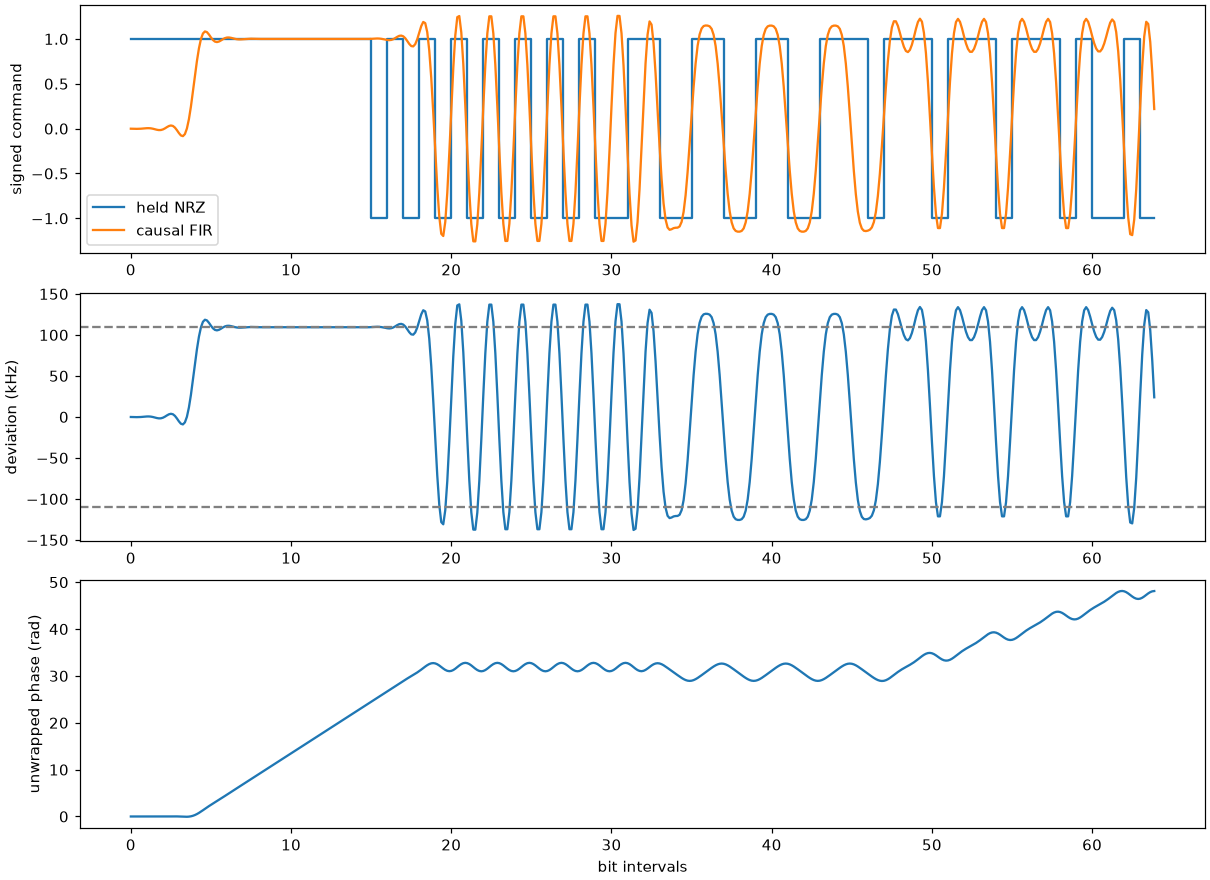

In [2]:
fig, ax = plt.subplots(3,1,figsize=(11,8),constrained_layout=True)
t = np.arange(512)/SPS
ax[0].step(t,nrz[:512],where='post',label='held NRZ'); ax[0].plot(t,shaped[:512],label='causal FIR'); ax[0].legend()
ax[0].set_ylabel('signed command')
ax[1].plot(t,shaped[:512]*DEVIATION/1000); ax[1].axhline(DEVIATION/1000,color='gray',ls='--'); ax[1].axhline(-DEVIATION/1000,color='gray',ls='--'); ax[1].set_ylabel('deviation (kHz)')
ax[2].plot(t,phase[:512]); ax[2].set_ylabel('unwrapped phase (rad)'); ax[2].set_xlabel('bit intervals')
fig.savefig('results/stages.png',dpi=150)
plt.show()

## 2. Frequency integrates into phase, then I/Q

For sample n, f[n] = Δf × shaped[n]. The phase update is φ[n] = φ[n−1] + 2π f[n]/Fs, starting with φ[−1] = 0. Output uses the updated phase: I[n] = A cos(φ[n]), Q[n] = A sin(φ[n]), with A = 16384.

The ideal envelope is constant. Wrapping numerical phase modulo 2π does not create a waveform discontinuity. The positive sign convention makes a positive command rotate counterclockwise in the I/Q plane.

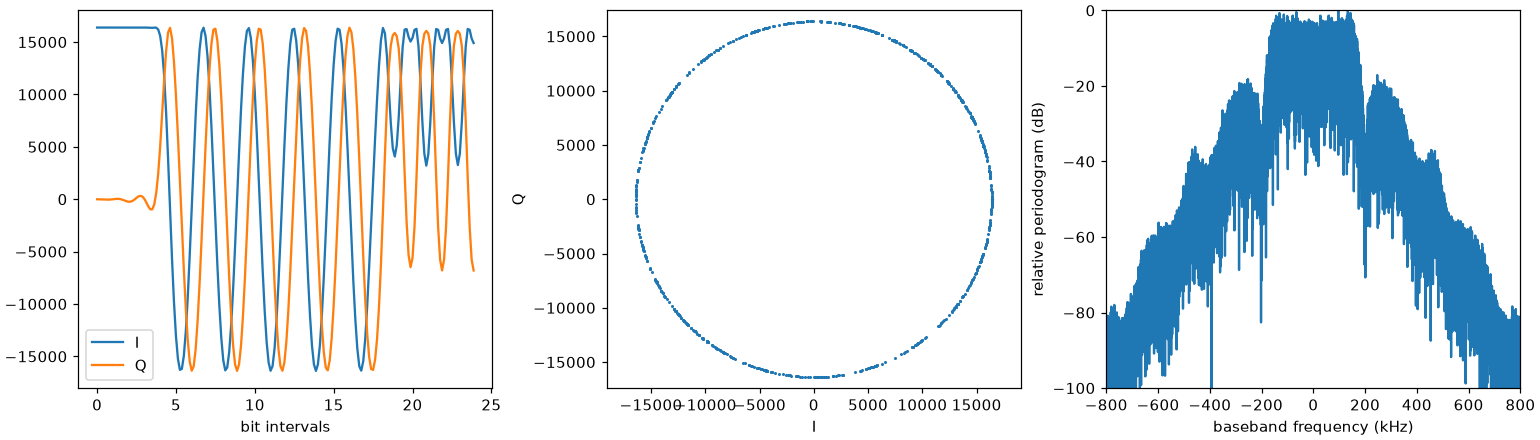

In [3]:
fig, ax = plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
ax[0].plot(np.arange(192)/SPS,ideal.real[:192],label='I'); ax[0].plot(np.arange(192)/SPS,ideal.imag[:192],label='Q'); ax[0].legend(); ax[0].set_xlabel('bit intervals')
ax[1].plot(ideal.real[:1024],ideal.imag[:1024],'.',ms=2); ax[1].axis('equal'); ax[1].set_xlabel('I'); ax[1].set_ylabel('Q')
z=ideal[1024:1024+65536]; w=np.hanning(len(z)); p=abs(np.fft.fftshift(np.fft.fft(z*w)))**2
f=np.fft.fftshift(np.fft.fftfreq(len(z),1/FS))
ax[2].plot(f/1000,10*np.log10(np.maximum(p/p.max(),1e-12))); ax[2].set_xlim(-800,800); ax[2].set_ylim(-100,0); ax[2].set_xlabel('baseband frequency (kHz)'); ax[2].set_ylabel('relative periodogram (dB)')
fig.savefig('results/iq-spectrum.png',dpi=150)
plt.show()

## 3. Replace real numbers with an explicit integer contract

| Stage | Representation / rule |
|---|---|
| NRZ history | signed 2-bit −1/+1; zero only in reset history |
| FIR coefficients | signed 18-bit integers, 17 fractional bits; symmetric; sum exactly 131072 |
| FIR accumulator | signed 21-bit; no intermediate rounding |
| Deviation gain | 187904819, unsigned 28-bit phase units per sample at unit command |
| Multiply | signed 50-bit, then shift right 17 with nearest rounding, ties away from zero |
| Phase increment | signed 32-bit |
| Phase accumulator | unsigned 32-bit, wraps modulo 2³² |
| Sine address | upper 12 phase bits; lower bits discarded |
| I/Q | sine ROM with 4096 signed 16-bit entries, amplitude 16384; cosine uses quarter-cycle offset |

Coefficients and ROM are rounded with NumPy nearest-even during table generation. The runtime multiply has a separately specified ties-away rule. A full sine ROM is 65536 bits; eventual FPGA mapping is not yet measured.

`valid=False` freezes FIR history, phase, and output. Reset clears FIR and phase. Each valid call represents one accepted sample; an HDL pipeline may add latency, which must be tracked with valid signals. This model does not specify clock-cycle scheduling, backpressure wiring, or an achievable FPGA clock rate.

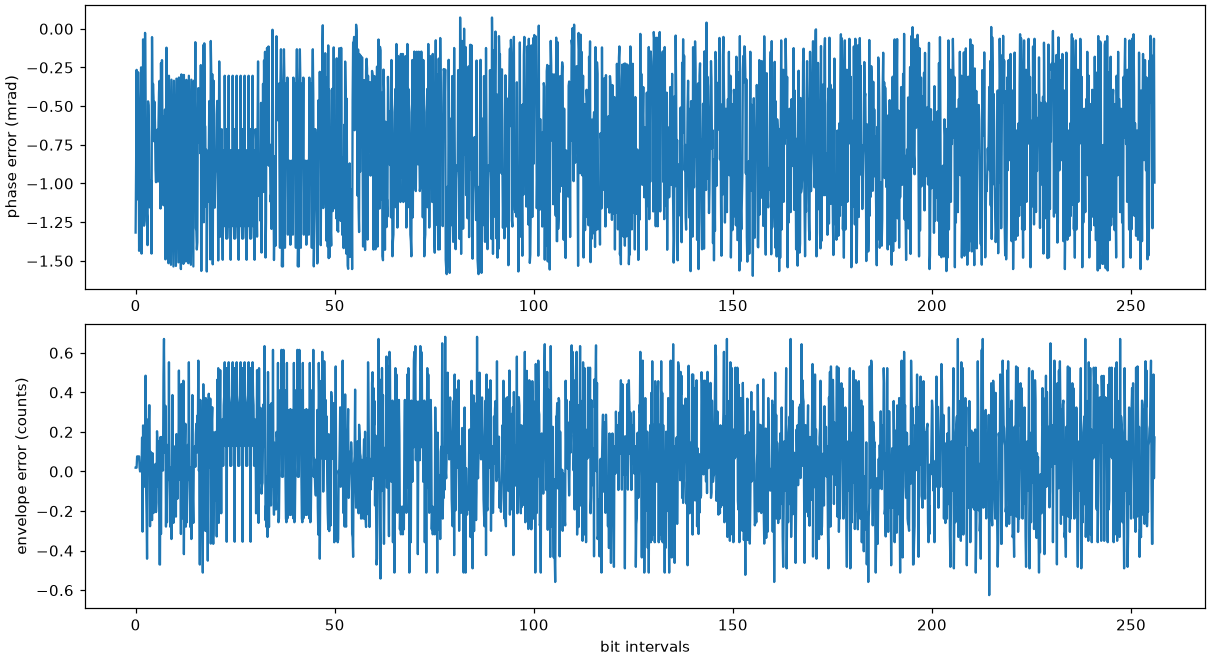

RMS I/Q error: 0.08901 %


In [4]:
actual = rows[:,3] + 1j*rows[:,4]
fig, ax = plt.subplots(2,1,figsize=(11,6),constrained_layout=True)
ax[0].plot(np.arange(2048)/SPS,np.angle(actual[:2048]*np.conj(ideal[:2048]))*1000); ax[0].set_ylabel('phase error (mrad)')
ax[1].plot(np.arange(2048)/SPS,abs(actual[:2048])-AMPLITUDE); ax[1].set_ylabel('envelope error (counts)'); ax[1].set_xlabel('bit intervals')
fig.savefig('results/integer-error.png',dpi=150)
plt.show()
print('RMS I/Q error: %.5f %%' % (100*metrics['relative_iq_rms_error']))

## 4. Evidence and handoff to HDL

The executed checks cover a full 32767-bit PN15 period, sequence balance and repetition, constant positive/negative levels, alternating bits, independent convolution versus streaming FIR, phase wrap, reset and deterministic random stalls. Comparison uses identical startup state with no phase fitting or time alignment.

`results/hdl_vectors.csv` contains 4096 accepted samples, with NRZ input, FIR sum, increment, phase and I/Q expected outputs. `coefficients_q17.txt` and `sine_lut_s16.txt` are the exact integer tables. `metrics.json` records measured errors. Run `python pcm_fm.py` to regenerate checks and vectors; run `python make_notebook.py` to regenerate this executed notebook and plots.

**Next, not implemented here:** agree the shaping response; schedule FIR/phase/ROM VHDL; compare HDL samples against these vectors including stalls and latency; integrate with the proven Pluto TX adapter; then use Vivado timing/resource reports and a new attenuated cable test. The previous BPSK image is untouched.